<a href="https://colab.research.google.com/github/sejalkubal18/CSL701-CE21_Machine-Learning-Lab/blob/main/ML_Experiment_5_s.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Aim : To implement a Bagging (Bootstrap Aggregating) ensemble classifier from scratch using Python, apply it to the Pima Indians Diabetes Database, and evaluate its performance against a single base classifier (Decision Tree)**.


## Objectives

1. Understand Ensemble Learning Principles: Comprehend how combining the predictions of multiple diverse models reduces overall model variance.
2. Master Bootstrapping: Implement random resampling of data with replacement from scratch to generate distinct training subsets.
3. Develop a Voting System: Build an aggregation mechanism (Majority Voting) from scratch to consolidate predictions.
4. Learn Baseline Evaluation: Compare the performance of a high-variance, low-bias single decision tree against the more stable Bagging ensemble.
5. Analyze Performance Metrics: Calculate and visualize classification metrics, including a Confusion Matrix, Accuracy, Precision, Recall, and ROC-AUC curve.


Relevant Theory
Ensemble Methods and Bagging
Ensemble learning combines several individual classifiers (base learners) to produce a unified model that generalizes better than any single model on unseen data. Bootstrap Aggregating (Bagging) is a parallel ensemble method designed primarily to reduce variance. High-variance models—such as deep, fully-grown decision trees—are highly sensitive to small changes in their training datasets. Bagging addresses this by smoothing out individual model errors without increasing bias.

The two core components of Bagging are:

1. Bootstrapping (Sampling with Replacement): For a training set of size $N$, we generate $B$ new datasets of the same size $N$. Each instance is selected at random from the original dataset with replacement. This means a single instance can be selected multiple times, while on average, only about 63.2% of the unique training samples are captured in each bootstrap, leaving the rest as out-of-bag (OOB) samples.
2. Aggregating (Majority Voting): A separate base learner $h_b(x)$ is trained independently on each bootstrap sample. For classification, predictions are aggregated by passing a test sample to all $B$ models and taking a majority vote: $$\hat{G}{\text{bag}}(x) = \text{argmax}{k} \sum_{b=1}^{B} I(h_b(x) = k)$$

An alternative to standard Bagging is subagging (subsample aggregating), where smaller training subsets (often $N/2$) are drawn without replacement to reduce correlation and accelerate computation.

---
## Software Requirements

- **Language:** Python 3.x

- **Core Libraries:**
  - **NumPy** for matrix manipulation and custom bootstrapping operations.
  - **Pandas** for loading, indexing, and cleaning tabular data.
  - **Matplotlib / Seaborn** for exploratory scatter plots, bar charts, and performance visualization.
  - **Scikit-learn** for train-test splitting, training individual base decision trees, and comparison with built-in Bagging algorithms.

---

## Dataset Information

The experiment utilizes the **Pima Indians Diabetes Database** from the UCI Machine Learning Repository. The dataset contains medical details for 768 female Pima Indian patients living in Arizona, categorized as either diabetic or non-diabetic.

- **Total Instances:** 768

- **Features (8 predictor variables):**
  1. **`Pregnancies`**: Number of times pregnant.
  2. **`Glucose`**: Plasma glucose concentration over 2 hours in an oral glucose tolerance test.
  3. **`BloodPressure`**: Diastolic blood pressure (mm Hg).
  4. **`SkinThickness`**: Triceps skin fold thickness (mm).
  5. **`Insulin`**: 2-Hour serum insulin ($\mu$U/ml).
  6. **`BMI`**: Body mass index (weight in kg/m$^2$).
  7. **`DiabetesPedigreeFunction`**: A function representing genetic predisposition.
  8. **`Age`**: Age of the subject in years.

- **Target Label (9th column):** **`Outcome`**
  - **0** represents non-diabetic.
  - **1** represents diabetic.

## Experimental Tasks

### Task 1: Environment Setup and Dataset Acquisition

Use dataset using the link  
https://www.kaggle.com/datasets/jamaltariqcheema/pima-indians-diabetes-dataset

**Goal:** Set up the workspace and load the data.

**Instructions:**

1. Import the necessary modules: **`numpy`**, **`pandas`**, **`matplotlib.pyplot`**, and **`sklearn`**.

2. Load the file **`pima-indians-diabetes.data`** into a Pandas DataFrame, assigning appropriate column headers.

3. Print the following:
   - First five records of the dataset.
   - Dataset shape, expected to be $768 \times 9$.
   - Data types of all features.
   - Descriptive statistics of the numeric features.

In [1]:
# ================================================================
# ML EXPERIMENT 5
# BAGGING (BOOTSTRAP AGGREGATING) ENSEMBLE CLASSIFIER
# ================================================================

# ================================================================
# TASK 1: ENVIRONMENT SETUP AND DATASET ACQUISITION
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    auc
)
from sklearn.ensemble import BaggingClassifier

print("=" * 70)
print("TASK 1: ENVIRONMENT SETUP AND DATASET ACQUISITION")
print("=" * 70)

# Column names
columns = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Outcome'
]

# Dataset URL
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

# Load dataset
df = pd.read_csv(url, names=columns)

print("\nFirst Five Records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nDescriptive Statistics:")
print(df.describe())


TASK 1: ENVIRONMENT SETUP AND DATASET ACQUISITION

First Five Records:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset Shape:
(768, 9)

Data Types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI           

## Task 2: Exploratory Data Analysis (EDA)

**Goal:** Visually inspect feature distributions and class balance.

**Instructions:**

1. Calculate the **absolute count** and **percentage** of diabetic (`Outcome = 1`) and non-diabetic (`Outcome = 0`) cases. Plot the class balance using a **bar chart**.

2. Create a **scatter plot** of **`Age`** (Feature 7) against **`Glucose`** (Feature 1), color-coded according to the target variable **`Outcome`**.

3. Briefly explain why a simple linear decision boundary is insufficient to clearly separate the diabetic and non-diabetic classes.


TASK 2: EXPLORATORY DATA ANALYSIS

Class Counts:
Non-Diabetic (0): 500
Diabetic (1): 268

Class Percentages:
Non-Diabetic (0): 65.1 %
Diabetic (1): 34.9 %


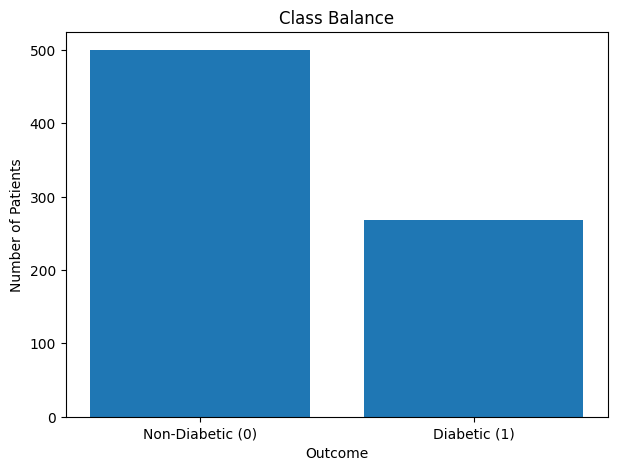

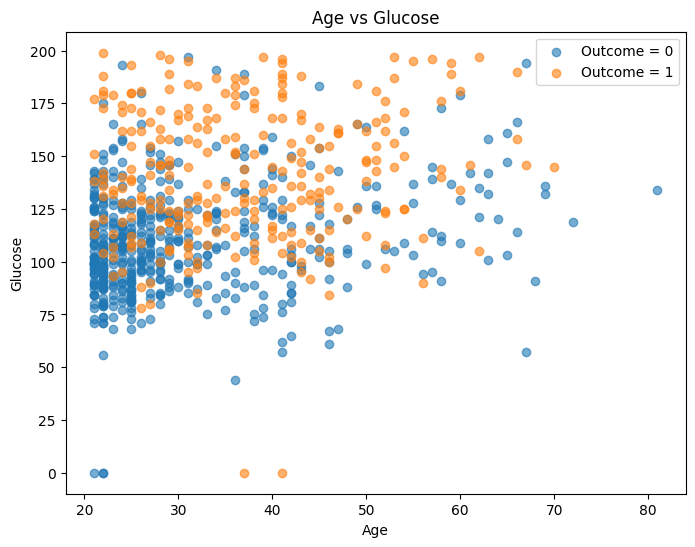


Why is a simple linear decision boundary insufficient?

The diabetic and non-diabetic classes overlap in the feature space.
Diabetes depends on several features together, such as Glucose,
BMI, Age, Pregnancies and BloodPressure. Therefore, a single
straight-line boundary cannot clearly separate all the classes.
A Decision Tree can create non-linear decision boundaries.



In [2]:
# ================================================================
# TASK 2: EXPLORATORY DATA ANALYSIS (EDA)
# ================================================================

print("\n" + "=" * 70)
print("TASK 2: EXPLORATORY DATA ANALYSIS")
print("=" * 70)

# Absolute count
class_counts = df['Outcome'].value_counts().sort_index()

# Percentage
class_percentages = (
    df['Outcome']
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("\nClass Counts:")
print("Non-Diabetic (0):", class_counts[0])
print("Diabetic (1):", class_counts[1])

print("\nClass Percentages:")
print("Non-Diabetic (0):", round(class_percentages[0], 2), "%")
print("Diabetic (1):", round(class_percentages[1], 2), "%")


# Class balance bar chart
plt.figure(figsize=(7, 5))

plt.bar(
    ['Non-Diabetic (0)', 'Diabetic (1)'],
    class_counts.values
)

plt.xlabel("Outcome")
plt.ylabel("Number of Patients")
plt.title("Class Balance")

plt.show()


# Age vs Glucose scatter plot
plt.figure(figsize=(8, 6))

for outcome in [0, 1]:

    subset = df[df['Outcome'] == outcome]

    plt.scatter(
        subset['Age'],
        subset['Glucose'],
        label=f'Outcome = {outcome}',
        alpha=0.6
    )

plt.xlabel("Age")
plt.ylabel("Glucose")
plt.title("Age vs Glucose")
plt.legend()

plt.show()

print("\nWhy is a simple linear decision boundary insufficient?")
print("""
The diabetic and non-diabetic classes overlap in the feature space.
Diabetes depends on several features together, such as Glucose,
BMI, Age, Pregnancies and BloodPressure. Therefore, a single
straight-line boundary cannot clearly separate all the classes.
A Decision Tree can create non-linear decision boundaries.
""")


#### **Task 3: Preprocessing and Handling Missing Values**

**Goal:** Handle anomalies and prepare numerical features for further analysis.

**Instructions:**

1. Identify the features where a value of \(0\) is physically impossible:
   \[
   \{\text{Glucose},\text{BloodPressure},\text{SkinThickness},
   \text{Insulin},\text{BMI}\}
   \]

2. Replace all invalid \(0\) values in these features with \(\mathrm{NaN}\).

3. Handle the resulting missing values by:
   - imputing them using the **mean** or **median** of the respective feature, or
   - dropping rows containing missing values to maintain numerical consistency.

In [3]:
# Task 3: Preprocessing and Handling Missing Values

# Make a copy
df_clean = df.copy()

# Features where 0 is physically impossible
invalid_zero_features = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

# Replace 0 with NaN
df_clean[invalid_zero_features] = df_clean[
    invalid_zero_features
].replace(0, np.nan)

# Display missing values before imputation
print("Missing values before imputation:")
print(df_clean.isnull().sum())

# Median imputation
for column in invalid_zero_features:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

# Check missing values after imputation
print("\nMissing values after imputation:")
print(df_clean.isnull().sum())

Missing values before imputation:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Missing values after imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


#### **Task 4: Stratified Train-Test Splitting**

**Goal:** Divide the data while preserving class proportions.

**Instructions:**

1. Isolate the feature matrix \(X\) and the target vector \(y\):
   \[
   X = \text{first 8 columns}
   \]
   \[
   y = \text{9th column}
   \]

2. Split the dataset into:
   \[
   \text{Training Data} = 80\%
   \]
   \[
   \text{Test Data} = 20\%
   \]

   Use **stratified sampling** to ensure that the class proportions in the target variable \(y\) are preserved in both the training and test datasets.

In [4]:
# Task 4: Stratified Train-Test Split

# Feature matrix
X = df_clean.iloc[:, :8]

# Target vector
y = df_clean.iloc[:, 8]

# 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training data shape: (614, 8)
Testing data shape: (154, 8)

Training class distribution:
Outcome
0    400
1    214
Name: count, dtype: int64

Testing class distribution:
Outcome
0    100
1     54
Name: count, dtype: int64


#### **Task 5: Custom Bootstrap Sampling Function**

**Goal:** Implement the sampling-with-replacement mechanism.

**Instructions:**

1. Write a custom Python function \(\texttt{get\_bootstrap\_sample}(X, y)\) using NumPy's random generation tools, such as:
   \[
   \texttt{np.random.choice}
   \quad \text{or} \quad
   \texttt{np.random.randint}
   \]

2. The function must return a resampled feature matrix \(X^*\) and target vector \(y^*\) of the same size \(N\) as the training set:
   \[
   |X^*| = |y^*| = N
   \]
   
   Sampling should be performed **with replacement**, allowing duplicate rows to appear in the bootstrap sample.

3. Verify that the function works correctly by demonstrating that:
   - Some original row indices are **duplicated** in the bootstrap sample.
   - Some original row indices are **omitted**, forming the **Out-of-Bag (OOB)** samples.

In [5]:
# Task 5: Custom Bootstrap Sampling

def get_bootstrap_sample(X, y):

    # Number of training samples
    n_samples = len(X)

    # Random indices with replacement
    indices = np.random.choice(
        n_samples,
        size=n_samples,
        replace=True
    )

    # Bootstrap samples
    X_bootstrap = X.iloc[indices].reset_index(drop=True)
    y_bootstrap = y.iloc[indices].reset_index(drop=True)

    return X_bootstrap, y_bootstrap, indices


# Test the bootstrap function
X_boot, y_boot, selected_indices = get_bootstrap_sample(
    X_train,
    y_train
)

print("Original training size:", len(X_train))
print("Bootstrap sample size:", len(X_boot))

print("\nFirst 20 selected indices:")
print(selected_indices[:20])

# Find duplicated indices
unique_indices, counts = np.unique(
    selected_indices,
    return_counts=True
)

duplicated_indices = unique_indices[counts > 1]

# Find OOB indices
all_indices = set(range(len(X_train)))
selected_unique = set(selected_indices)

oob_indices = sorted(
    all_indices - selected_unique
)

print("\nNumber of duplicated indices:",
      len(duplicated_indices))

print("Number of OOB samples:",
      len(oob_indices))

print("\nSome duplicated indices:")
print(duplicated_indices[:10])

print("\nSome OOB indices:")
print(oob_indices[:10])

Original training size: 614
Bootstrap sample size: 614

First 20 selected indices:
[607  96 514 545 432 131 427 342 252  71 128 458 304 585 514  79 467 224
 341 104]

Number of duplicated indices: 167
Number of OOB samples: 220

Some duplicated indices:
[10 14 21 23 26 33 35 37 40 42]

Some OOB indices:
[1, 3, 4, 5, 6, 13, 16, 17, 18, 19]


#### **Task 6: Growing the Ensemble of Base Classifiers**

**Goal:** Programmatically train diverse base learners.

**Instructions:**

1. Initialize an empty list to store the trained models and choose the number of bootstrap iterations, for example:
   \[
   B = 50
   \]

2. Execute the following steps for \(B\) iterations:

   - Generate a unique bootstrap training dataset:
     \[
     (X^{*b}, y^{*b})
     \]
     using the bootstrap sampling function from **Task 5**.

   - Instantiate a Scikit-Learn `DecisionTreeClassifier` with:
     \[
     \texttt{max\_depth=None}
     \]
     This ensures that the decision trees are **fully grown**, resulting in high-variance base learners.

   - Fit the decision tree on the bootstrapped training subset:
     \[
     \text{Model}_b.fit(X^{*b}, y^{*b})
     \]

   - Append the trained model to the ensemble list.

3. After completing all \(B\) iterations, the ensemble should contain:
   \[
   B = 50
   \]
   independently trained decision trees.

In [6]:
# ================================================================
# TASK 6: GROWING THE ENSEMBLE OF BASE CLASSIFIERS
# ================================================================

print("\n" + "=" * 70)
print("TASK 6: GROWING THE ENSEMBLE")
print("=" * 70)

# Number of bootstrap iterations / trees
B = 50

# Empty list for trained models
ensemble = []

# Set seed
np.random.seed(42)

# Train 50 Decision Trees
for b in range(B):

    # Generate bootstrap sample
    X_bootstrap, y_bootstrap, indices = get_bootstrap_sample(
        X_train,
        y_train
    )

    # Fully grown Decision Tree
    tree = DecisionTreeClassifier(
        max_depth=None,
        random_state=42 + b
    )

    # Train tree
    tree.fit(
        X_bootstrap,
        y_bootstrap
    )

    # Store model
    ensemble.append(tree)

print("\nNumber of trees in ensemble:", len(ensemble))


TASK 6: GROWING THE ENSEMBLE

Number of trees in ensemble: 50


#### **Task 7: Implementing Aggregation (Majority Voting) from Scratch**

**Goal:** Consolidate individual model decisions using majority voting.

**Instructions:**

1. Write a custom function:
   \[
   \texttt{custom\_bagging\_predict(ensemble, X\_test)}
   \]
   to generate the final predictions.

2. For each sample in \(X_{\text{test}}\), collect the predictions generated by all \(B\) decision trees in the ensemble:
   \[
   \hat{y}_1,\hat{y}_2,\ldots,\hat{y}_B
   \]

3. Apply a **majority voting** rule to determine the final predicted class. The class with the highest number of votes is selected:
   \[
   \hat{y} =
   \underset{c \in \{0,1\}}{\arg\max}
   \sum_{b=1}^{B} I(\hat{y}_b=c)
   \]

   where \(I(\cdot)\) is an indicator function.

4. The final prediction for each test sample must therefore be either:
   \[
   \hat{y} \in \{0,1\}
   \]

5. The function should return the final majority-voted predictions for all samples in \(X_{\text{test}}\).

In [7]:
# ================================================================
# TASK 7: MAJORITY VOTING FROM SCRATCH
# ================================================================

print("\n" + "=" * 70)
print("TASK 7: IMPLEMENTING MAJORITY VOTING")
print("=" * 70)


def custom_bagging_predict(ensemble, X_test):

    # Store predictions from every tree
    all_predictions = []

    for tree in ensemble:

        predictions = tree.predict(X_test)

        all_predictions.append(predictions)

    # Convert list to NumPy array
    all_predictions = np.array(all_predictions)

    # Store final predictions
    final_predictions = []

    # Process each test sample
    for i in range(X_test.shape[0]):

        # Get predictions of all trees
        votes = all_predictions[:, i]

        # Count votes
        votes_class_0 = np.sum(votes == 0)
        votes_class_1 = np.sum(votes == 1)

        # Majority voting
        if votes_class_1 > votes_class_0:
            final_predictions.append(1)
        else:
            final_predictions.append(0)

    return np.array(final_predictions)


# Generate final Bagging predictions
y_pred_bagging = custom_bagging_predict(
    ensemble,
    X_test
)

print("\nFirst 20 Bagging Predictions:")
print(y_pred_bagging[:20])

print("\nUnique Predicted Classes:")
print(np.unique(y_pred_bagging))



TASK 7: IMPLEMENTING MAJORITY VOTING

First 20 Bagging Predictions:
[1 0 0 0 0 0 0 1 0 1 1 1 0 0 0 0 1 0 1 0]

Unique Predicted Classes:
[0 1]


#### **Task 8: Single Classifier vs. Bagging Performance Comparison**

- **Goal:** Observe the variance-reduction benefits of ensembling.

- **Instructions:**
  1. Train a standalone, single \(\texttt{DecisionTreeClassifier}\) (fully grown, no depth limit) on the original, un-resampled training data.
  2. Predict the classes for \(X_{\text{test}}\) using both the single tree and your custom Bagging classifier.
  3. Construct a **Confusion Matrix** for both models.
  4. Compute and print **Accuracy, Precision, Recall, and F1-Score** for both models, demonstrating how Bagging stabilizes results and reduces error rates.

In [8]:

# ================================================================
# TASK 8: SINGLE DECISION TREE VS BAGGING
# ================================================================

print("\n" + "=" * 70)
print("TASK 8: SINGLE CLASSIFIER VS BAGGING")
print("=" * 70)


# ------------------------------------------------
# Train Single Decision Tree
# ------------------------------------------------

single_tree = DecisionTreeClassifier(
    max_depth=None,
    random_state=42
)

single_tree.fit(
    X_train,
    y_train
)

# Predictions
y_pred_tree = single_tree.predict(X_test)


# ------------------------------------------------
# Evaluation Function
# ------------------------------------------------

def evaluate_model(name, y_true, y_pred):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    print("\n----------------------------------------")
    print(name)
    print("----------------------------------------")

    print("\nConfusion Matrix:")
    print(cm)

    print("\nAccuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1-Score :", round(f1, 4))

    return accuracy, precision, recall, f1, cm


# Evaluate Single Tree
tree_results = evaluate_model(
    "Single Decision Tree",
    y_test,
    y_pred_tree
)


# Evaluate Custom Bagging
bagging_results = evaluate_model(
    "Custom Bagging Classifier",
    y_test,
    y_pred_bagging
)



TASK 8: SINGLE CLASSIFIER VS BAGGING

----------------------------------------
Single Decision Tree
----------------------------------------

Confusion Matrix:
[[79 21]
 [28 26]]

Accuracy : 0.6818
Precision: 0.5532
Recall   : 0.4815
F1-Score : 0.5149

----------------------------------------
Custom Bagging Classifier
----------------------------------------

Confusion Matrix:
[[86 14]
 [24 30]]

Accuracy : 0.7532
Precision: 0.6818
Recall   : 0.5556
F1-Score : 0.6122


#### **Task 9: ROC-AUC Analysis and Curve Visualization**

- **Goal:** Measure classification performance at different thresholds.

- **Instructions:**
  1. Calculate predicted class probabilities by averaging the probability estimates (\(\texttt{predict\_proba}\)) across all \(B\) decision trees in your custom Bagging model.
  2. Plot the **Receiver Operating Characteristic (ROC) curve** for both the single decision tree and the custom Bagging model on a single chart.
  3. Compute and contrast the **Area Under the Curve (AUC)** for both configurations, noting the improvement.


TASK 9: ROC-AUC ANALYSIS


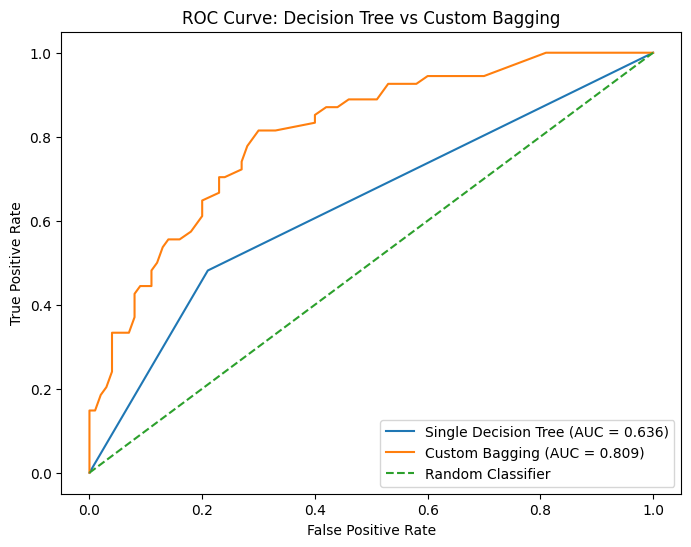


Single Decision Tree AUC: 0.6357
Custom Bagging AUC: 0.8089


In [9]:

# ================================================================
# TASK 9: ROC-AUC ANALYSIS
# ================================================================

print("\n" + "=" * 70)
print("TASK 9: ROC-AUC ANALYSIS")
print("=" * 70)


# ------------------------------------------------
# Single Tree Probability
# ------------------------------------------------

y_prob_tree = single_tree.predict_proba(
    X_test
)[:, 1]


# ------------------------------------------------
# Custom Bagging Probability
# ------------------------------------------------

all_probabilities = []

for tree in ensemble:

    probabilities = tree.predict_proba(
        X_test
    )[:, 1]

    all_probabilities.append(probabilities)

# Convert to NumPy array
all_probabilities = np.array(
    all_probabilities
)

# Average probability across all trees
y_prob_bagging = np.mean(
    all_probabilities,
    axis=0
)


# ------------------------------------------------
# ROC Curves
# ------------------------------------------------

fpr_tree, tpr_tree, _ = roc_curve(
    y_test,
    y_prob_tree
)

fpr_bagging, tpr_bagging, _ = roc_curve(
    y_test,
    y_prob_bagging
)


# ------------------------------------------------
# Calculate AUC
# ------------------------------------------------

auc_tree = auc(
    fpr_tree,
    tpr_tree
)

auc_bagging = auc(
    fpr_bagging,
    tpr_bagging
)


# ------------------------------------------------
# Plot ROC Curves
# ------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_tree,
    tpr_tree,
    label=f'Single Decision Tree (AUC = {auc_tree:.3f})'
)

plt.plot(
    fpr_bagging,
    tpr_bagging,
    label=f'Custom Bagging (AUC = {auc_bagging:.3f})'
)

# Random classifier line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Decision Tree vs Custom Bagging")
plt.legend()

plt.show()

print("\nSingle Decision Tree AUC:",
      round(auc_tree, 4))

print("Custom Bagging AUC:",
      round(auc_bagging, 4))

#### **Task 10: Validation against Scikit-Learn's BaggingClassifier**

- **Goal:** Verify custom code correctness.

- **Instructions:**
  1. Instantiate Scikit-Learn's built-in \(\texttt{BaggingClassifier}\) using \(\texttt{DecisionTreeClassifier(max\_depth=None)}\) as the base estimator and \(\texttt{n\_estimators=50}\).
  2. Fit the classifier on the training set and evaluate it on the test set.
  3. Compare the resulting test accuracy and confusion matrix against your custom implementation from **Task 7** and **Task 8** to validate your custom bootstrap and aggregation logic.

In [10]:

# ================================================================
# TASK 10: VALIDATION USING SCIKIT-LEARN BAGGINGCLASSIFIER
# ================================================================

print("\n" + "=" * 70)
print("TASK 10: SCIKIT-LEARN BAGGING CLASSIFIER")
print("=" * 70)


# Base Decision Tree
base_tree = DecisionTreeClassifier(
    max_depth=None,
    random_state=42
)


# ------------------------------------------------
# Create Built-in Bagging Classifier
# ------------------------------------------------

sklearn_bagging = BaggingClassifier(
    estimator=base_tree,
    n_estimators=50,
    random_state=42
)


# Train
sklearn_bagging.fit(
    X_train,
    y_train
)


# Predict
y_pred_sklearn = sklearn_bagging.predict(
    X_test
)


# Evaluate
sklearn_results = evaluate_model(
    "Scikit-Learn BaggingClassifier",
    y_test,
    y_pred_sklearn
)




TASK 10: SCIKIT-LEARN BAGGING CLASSIFIER

----------------------------------------
Scikit-Learn BaggingClassifier
----------------------------------------

Confusion Matrix:
[[85 15]
 [26 28]]

Accuracy : 0.7338
Precision: 0.6512
Recall   : 0.5185
F1-Score : 0.5773


In [ ]:

# ================================================================
# FINAL COMPARISON
# ================================================================

print("\n" + "=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)


comparison = pd.DataFrame({

    'Model': [
        'Single Decision Tree',
        'Custom Bagging',
        'Scikit-Learn Bagging'
    ],

    'Accuracy': [
        tree_results[0],
        bagging_results[0],
        sklearn_results[0]
    ],

    'Precision': [
        tree_results[1],
        bagging_results[1],
        sklearn_results[1]
    ],

    'Recall': [
        tree_results[2],
        bagging_results[2],
        sklearn_results[2]
    ],

    'F1-Score': [
        tree_results[3],
        bagging_results[3],
        sklearn_results[3]
    ]
})


print(
    comparison.round(4).to_string(index=False)
)


# ================================================================
# CONFUSION MATRIX COMPARISON
# ================================================================

print("\n" + "=" * 70)
print("CONFUSION MATRICES")
print("=" * 70)

print("\nSingle Decision Tree:")
print(tree_results[4])

print("\nCustom Bagging:")
print(bagging_results[4])

print("\nScikit-Learn Bagging:")
print(sklearn_results[4])


# ================================================================
# FINAL OBSERVATION
# ================================================================

print("\n" + "=" * 70)
print("FINAL OBSERVATION")
print("=" * 70)

print("""
1. A single fully grown Decision Tree can have high variance because
   it is sensitive to changes in the training data.

2. Bagging trains multiple Decision Trees using different bootstrap
   samples.

3. Majority voting combines the predictions of all 50 trees.

4. Bagging generally reduces variance and provides more stable
   predictions than a single Decision Tree.

5. Recall is especially important in diabetes classification because
   False Negatives represent diabetic patients predicted as
   non-diabetic.

6. The custom Bagging implementation can be compared with
   Scikit-Learn's BaggingClassifier to validate the implementation.

7. ROC-AUC provides another way to compare the classification
   performance of the models across different thresholds.
""")

print("\n" + "=" * 70)
print("EXPERIMENT 5 COMPLETED SUCCESSFULLY")
print("=" * 70)

TASK 1: ENVIRONMENT SETUP AND DATASET ACQUISITION

First Five Records:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset Shape:
(768, 9)

Data Types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI           

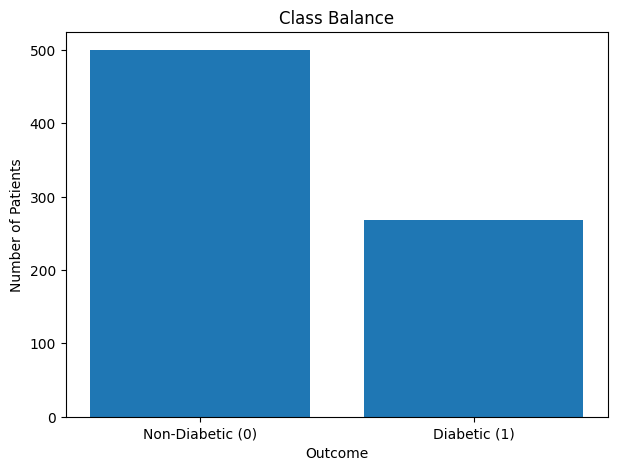

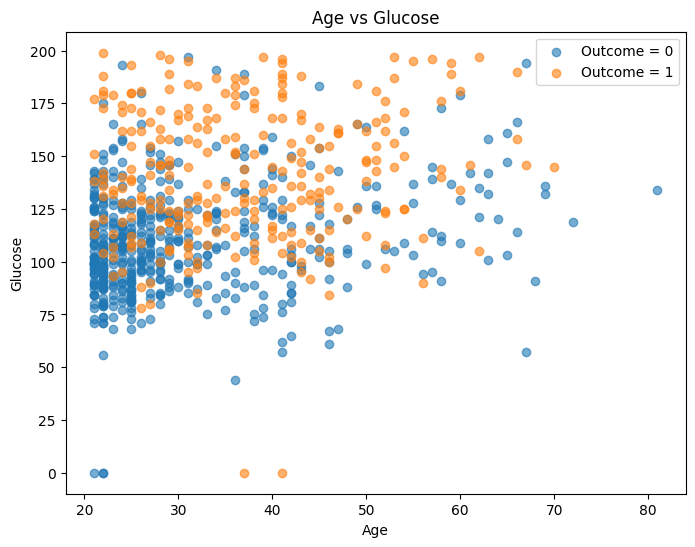


Why is a simple linear decision boundary insufficient?

The diabetic and non-diabetic classes overlap in the feature space.
Diabetes depends on several features together, such as Glucose,
BMI, Age, Pregnancies and BloodPressure. Therefore, a single
straight-line boundary cannot clearly separate all the classes.
A Decision Tree can create non-linear decision boundaries.


TASK 3: PREPROCESSING AND HANDLING MISSING VALUES

Features where 0 is treated as invalid:
['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

Missing values BEFORE imputation:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Missing values AFTER imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickn

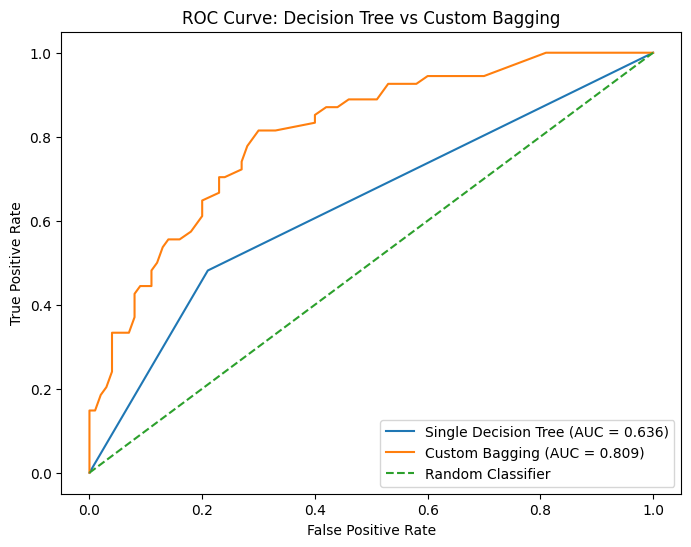


Single Decision Tree AUC: 0.6357
Custom Bagging AUC: 0.8089

TASK 10: SCIKIT-LEARN BAGGING CLASSIFIER

----------------------------------------
Scikit-Learn BaggingClassifier
----------------------------------------

Confusion Matrix:
[[85 15]
 [26 28]]

Accuracy : 0.7338
Precision: 0.6512
Recall   : 0.5185
F1-Score : 0.5773

FINAL MODEL COMPARISON
               Model  Accuracy  Precision  Recall  F1-Score
Single Decision Tree    0.6818     0.5532  0.4815    0.5149
      Custom Bagging    0.7532     0.6818  0.5556    0.6122
Scikit-Learn Bagging    0.7338     0.6512  0.5185    0.5773

CONFUSION MATRICES

Single Decision Tree:
[[79 21]
 [28 26]]

Custom Bagging:
[[86 14]
 [24 30]]

Scikit-Learn Bagging:
[[85 15]
 [26 28]]

FINAL OBSERVATION

1. A single fully grown Decision Tree can have high variance because
   it is sensitive to changes in the training data.

2. Bagging trains multiple Decision Trees using different bootstrap
   samples.

3. Majority voting combines the predictions o

In [11]:
# ================================================================
# ML EXPERIMENT 5
# BAGGING (BOOTSTRAP AGGREGATING) ENSEMBLE CLASSIFIER
# ================================================================

# ================================================================
# TASK 1: ENVIRONMENT SETUP AND DATASET ACQUISITION
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    auc
)
from sklearn.ensemble import BaggingClassifier

print("=" * 70)
print("TASK 1: ENVIRONMENT SETUP AND DATASET ACQUISITION")
print("=" * 70)

# Column names
columns = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Outcome'
]

# Dataset URL
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

# Load dataset
df = pd.read_csv(url, names=columns)

print("\nFirst Five Records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nDescriptive Statistics:")
print(df.describe())


# ================================================================
# TASK 2: EXPLORATORY DATA ANALYSIS (EDA)
# ================================================================

print("\n" + "=" * 70)
print("TASK 2: EXPLORATORY DATA ANALYSIS")
print("=" * 70)

# Absolute count
class_counts = df['Outcome'].value_counts().sort_index()

# Percentage
class_percentages = (
    df['Outcome']
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("\nClass Counts:")
print("Non-Diabetic (0):", class_counts[0])
print("Diabetic (1):", class_counts[1])

print("\nClass Percentages:")
print("Non-Diabetic (0):", round(class_percentages[0], 2), "%")
print("Diabetic (1):", round(class_percentages[1], 2), "%")


# Class balance bar chart
plt.figure(figsize=(7, 5))

plt.bar(
    ['Non-Diabetic (0)', 'Diabetic (1)'],
    class_counts.values
)

plt.xlabel("Outcome")
plt.ylabel("Number of Patients")
plt.title("Class Balance")

plt.show()


# Age vs Glucose scatter plot
plt.figure(figsize=(8, 6))

for outcome in [0, 1]:

    subset = df[df['Outcome'] == outcome]

    plt.scatter(
        subset['Age'],
        subset['Glucose'],
        label=f'Outcome = {outcome}',
        alpha=0.6
    )

plt.xlabel("Age")
plt.ylabel("Glucose")
plt.title("Age vs Glucose")
plt.legend()

plt.show()

print("\nWhy is a simple linear decision boundary insufficient?")
print("""
The diabetic and non-diabetic classes overlap in the feature space.
Diabetes depends on several features together, such as Glucose,
BMI, Age, Pregnancies and BloodPressure. Therefore, a single
straight-line boundary cannot clearly separate all the classes.
A Decision Tree can create non-linear decision boundaries.
""")


# ================================================================
# TASK 3: PREPROCESSING AND HANDLING MISSING VALUES
# ================================================================

print("\n" + "=" * 70)
print("TASK 3: PREPROCESSING AND HANDLING MISSING VALUES")
print("=" * 70)

# Create a copy
df_clean = df.copy()

# Features where zero is physically impossible
invalid_zero_features = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

print("\nFeatures where 0 is treated as invalid:")
print(invalid_zero_features)

# Replace zero with NaN
df_clean[invalid_zero_features] = (
    df_clean[invalid_zero_features]
    .replace(0, np.nan)
)

print("\nMissing values BEFORE imputation:")
print(df_clean.isnull().sum())

# Median imputation
for column in invalid_zero_features:

    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

print("\nMissing values AFTER imputation:")
print(df_clean.isnull().sum())

print("\nData after preprocessing:")
print(df_clean.head())


# ================================================================
# TASK 4: STRATIFIED TRAIN-TEST SPLITTING
# ================================================================

print("\n" + "=" * 70)
print("TASK 4: STRATIFIED TRAIN-TEST SPLITTING")
print("=" * 70)

# Feature matrix - first 8 columns
X = df_clean.iloc[:, :8]

# Target vector - 9th column
y = df_clean.iloc[:, 8]

# 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())


# ================================================================
# TASK 5: CUSTOM BOOTSTRAP SAMPLING FUNCTION
# ================================================================

print("\n" + "=" * 70)
print("TASK 5: CUSTOM BOOTSTRAP SAMPLING")
print("=" * 70)


def get_bootstrap_sample(X, y):

    # Number of samples
    n_samples = len(X)

    # Random indices with replacement
    indices = np.random.choice(
        n_samples,
        size=n_samples,
        replace=True
    )

    # Create bootstrap sample
    X_bootstrap = X.iloc[indices].reset_index(drop=True)
    y_bootstrap = y.iloc[indices].reset_index(drop=True)

    return X_bootstrap, y_bootstrap, indices


# Test bootstrap function
np.random.seed(42)

X_boot, y_boot, selected_indices = get_bootstrap_sample(
    X_train,
    y_train
)

print("\nOriginal Training Size:", len(X_train))
print("Bootstrap Sample Size:", len(X_boot))

# Find duplicated indices
unique_indices, counts = np.unique(
    selected_indices,
    return_counts=True
)

duplicated_indices = unique_indices[counts > 1]

# Find OOB indices
all_indices = set(range(len(X_train)))
selected_unique = set(selected_indices)

oob_indices = sorted(
    all_indices - selected_unique
)

print("\nNumber of duplicated indices:",
      len(duplicated_indices))

print("Number of OOB samples:",
      len(oob_indices))

print("\nSome duplicated indices:")
print(duplicated_indices[:10])

print("\nSome OOB indices:")
print(oob_indices[:10])


# ================================================================
# TASK 6: GROWING THE ENSEMBLE OF BASE CLASSIFIERS
# ================================================================

print("\n" + "=" * 70)
print("TASK 6: GROWING THE ENSEMBLE")
print("=" * 70)

# Number of bootstrap iterations / trees
B = 50

# Empty list for trained models
ensemble = []

# Set seed
np.random.seed(42)

# Train 50 Decision Trees
for b in range(B):

    # Generate bootstrap sample
    X_bootstrap, y_bootstrap, indices = get_bootstrap_sample(
        X_train,
        y_train
    )

    # Fully grown Decision Tree
    tree = DecisionTreeClassifier(
        max_depth=None,
        random_state=42 + b
    )

    # Train tree
    tree.fit(
        X_bootstrap,
        y_bootstrap
    )

    # Store model
    ensemble.append(tree)

print("\nNumber of trees in ensemble:", len(ensemble))


# ================================================================
# TASK 7: MAJORITY VOTING FROM SCRATCH
# ================================================================

print("\n" + "=" * 70)
print("TASK 7: IMPLEMENTING MAJORITY VOTING")
print("=" * 70)


def custom_bagging_predict(ensemble, X_test):

    # Store predictions from every tree
    all_predictions = []

    for tree in ensemble:

        predictions = tree.predict(X_test)

        all_predictions.append(predictions)

    # Convert list to NumPy array
    all_predictions = np.array(all_predictions)

    # Store final predictions
    final_predictions = []

    # Process each test sample
    for i in range(X_test.shape[0]):

        # Get predictions of all trees
        votes = all_predictions[:, i]

        # Count votes
        votes_class_0 = np.sum(votes == 0)
        votes_class_1 = np.sum(votes == 1)

        # Majority voting
        if votes_class_1 > votes_class_0:
            final_predictions.append(1)
        else:
            final_predictions.append(0)

    return np.array(final_predictions)


# Generate final Bagging predictions
y_pred_bagging = custom_bagging_predict(
    ensemble,
    X_test
)

print("\nFirst 20 Bagging Predictions:")
print(y_pred_bagging[:20])

print("\nUnique Predicted Classes:")
print(np.unique(y_pred_bagging))


# ================================================================
# TASK 8: SINGLE DECISION TREE VS BAGGING
# ================================================================

print("\n" + "=" * 70)
print("TASK 8: SINGLE CLASSIFIER VS BAGGING")
print("=" * 70)


# ------------------------------------------------
# Train Single Decision Tree
# ------------------------------------------------

single_tree = DecisionTreeClassifier(
    max_depth=None,
    random_state=42
)

single_tree.fit(
    X_train,
    y_train
)

# Predictions
y_pred_tree = single_tree.predict(X_test)


# ------------------------------------------------
# Evaluation Function
# ------------------------------------------------

def evaluate_model(name, y_true, y_pred):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    print("\n----------------------------------------")
    print(name)
    print("----------------------------------------")

    print("\nConfusion Matrix:")
    print(cm)

    print("\nAccuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1-Score :", round(f1, 4))

    return accuracy, precision, recall, f1, cm


# Evaluate Single Tree
tree_results = evaluate_model(
    "Single Decision Tree",
    y_test,
    y_pred_tree
)


# Evaluate Custom Bagging
bagging_results = evaluate_model(
    "Custom Bagging Classifier",
    y_test,
    y_pred_bagging
)


# ================================================================
# TASK 9: ROC-AUC ANALYSIS
# ================================================================

print("\n" + "=" * 70)
print("TASK 9: ROC-AUC ANALYSIS")
print("=" * 70)


# ------------------------------------------------
# Single Tree Probability
# ------------------------------------------------

y_prob_tree = single_tree.predict_proba(
    X_test
)[:, 1]


# ------------------------------------------------
# Custom Bagging Probability
# ------------------------------------------------

all_probabilities = []

for tree in ensemble:

    probabilities = tree.predict_proba(
        X_test
    )[:, 1]

    all_probabilities.append(probabilities)

# Convert to NumPy array
all_probabilities = np.array(
    all_probabilities
)

# Average probability across all trees
y_prob_bagging = np.mean(
    all_probabilities,
    axis=0
)


# ------------------------------------------------
# ROC Curves
# ------------------------------------------------

fpr_tree, tpr_tree, _ = roc_curve(
    y_test,
    y_prob_tree
)

fpr_bagging, tpr_bagging, _ = roc_curve(
    y_test,
    y_prob_bagging
)


# ------------------------------------------------
# Calculate AUC
# ------------------------------------------------

auc_tree = auc(
    fpr_tree,
    tpr_tree
)

auc_bagging = auc(
    fpr_bagging,
    tpr_bagging
)


# ------------------------------------------------
# Plot ROC Curves
# ------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_tree,
    tpr_tree,
    label=f'Single Decision Tree (AUC = {auc_tree:.3f})'
)

plt.plot(
    fpr_bagging,
    tpr_bagging,
    label=f'Custom Bagging (AUC = {auc_bagging:.3f})'
)

# Random classifier line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Decision Tree vs Custom Bagging")
plt.legend()

plt.show()

print("\nSingle Decision Tree AUC:",
      round(auc_tree, 4))

print("Custom Bagging AUC:",
      round(auc_bagging, 4))


# ================================================================
# TASK 10: VALIDATION USING SCIKIT-LEARN BAGGINGCLASSIFIER
# ================================================================

print("\n" + "=" * 70)
print("TASK 10: SCIKIT-LEARN BAGGING CLASSIFIER")
print("=" * 70)


# Base Decision Tree
base_tree = DecisionTreeClassifier(
    max_depth=None,
    random_state=42
)


# ------------------------------------------------
# Create Built-in Bagging Classifier
# ------------------------------------------------

sklearn_bagging = BaggingClassifier(
    estimator=base_tree,
    n_estimators=50,
    random_state=42
)


# Train
sklearn_bagging.fit(
    X_train,
    y_train
)


# Predict
y_pred_sklearn = sklearn_bagging.predict(
    X_test
)


# Evaluate
sklearn_results = evaluate_model(
    "Scikit-Learn BaggingClassifier",
    y_test,
    y_pred_sklearn
)


# ================================================================
# FINAL COMPARISON
# ================================================================

print("\n" + "=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)


comparison = pd.DataFrame({

    'Model': [
        'Single Decision Tree',
        'Custom Bagging',
        'Scikit-Learn Bagging'
    ],

    'Accuracy': [
        tree_results[0],
        bagging_results[0],
        sklearn_results[0]
    ],

    'Precision': [
        tree_results[1],
        bagging_results[1],
        sklearn_results[1]
    ],

    'Recall': [
        tree_results[2],
        bagging_results[2],
        sklearn_results[2]
    ],

    'F1-Score': [
        tree_results[3],
        bagging_results[3],
        sklearn_results[3]
    ]
})


print(
    comparison.round(4).to_string(index=False)
)


# ================================================================
# CONFUSION MATRIX COMPARISON
# ================================================================

print("\n" + "=" * 70)
print("CONFUSION MATRICES")
print("=" * 70)

print("\nSingle Decision Tree:")
print(tree_results[4])

print("\nCustom Bagging:")
print(bagging_results[4])

print("\nScikit-Learn Bagging:")
print(sklearn_results[4])


# ================================================================
# FINAL OBSERVATION
# ================================================================

print("\n" + "=" * 70)
print("FINAL OBSERVATION")
print("=" * 70)

print("""
1. A single fully grown Decision Tree can have high variance because
   it is sensitive to changes in the training data.

2. Bagging trains multiple Decision Trees using different bootstrap
   samples.

3. Majority voting combines the predictions of all 50 trees.

4. Bagging generally reduces variance and provides more stable
   predictions than a single Decision Tree.

5. Recall is especially important in diabetes classification because
   False Negatives represent diabetic patients predicted as
   non-diabetic.

6. The custom Bagging implementation can be compared with
   Scikit-Learn's BaggingClassifier to validate the implementation.

7. ROC-AUC provides another way to compare the classification
   performance of the models across different thresholds.
""")

print("\n" + "=" * 70)
print("EXPERIMENT 5 COMPLETED SUCCESSFULLY")
print("=" * 70)


### **Conclusion and Interpretation**

Students should summarize their findings by answering the following key questions:

1. **Variance and Stability:** How does the test accuracy of the Bagging ensemble compare to the single decision tree? Why does Bagging provide more consistent performance across different train-test splits?

2. **Wisdom of Crowds:** How does random resampling with replacement (bootstrapping) foster model diversity, and how does the consensus voting rule translate to a "Wisdom of Crowds" effect?

3. **Clinical Interpretation:** In predicting diabetes, why are False Negatives (predicting non-diabetic for a diabetic patient) especially costly, and how does Bagging's Recall metric help minimize this risk compared to a single decision tree?